# Parts Tray Semantic Segmentation — From-Scratch U-Net

Pixel-level classification of six mechanical fastener classes (`hex_nut`, `washer`, `bolt`,
`ball_bearing`, `spring`, `o_ring`) plus background, scored with mean Dice over every
(image, class) pair.

**Structure:**
1. Setup & config
2. EDA
3. RLE encode/decode + competition metric (sanity-checked against the reference code)
4. Dataset & augmentation
5. From-scratch U-Net model
6. Combined CrossEntropy + Dice loss
7. Training loop with validation Dice tracking
8. Inference on test set → RLE → `submission.csv`


## 1. Setup & Config

In [1]:
import os, random, time, copy
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt

SEED = 44
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# --- Paths: auto-detected -------------------------------------------------
# Kaggle mounts the dataset under /kaggle/input/<slug>/..., and the exact slug
# and folder depth (e.g. an extra "Dataset" subfolder) can vary. Instead of
# hardcoding it, search for the folder that actually contains train/images,
# train/masks and test/images.
def _find_data_dir(root="/kaggle/input"):
    for dirpath, dirnames, filenames in os.walk(root):
        if "train" in dirnames and "test" in dirnames:
            train_images = os.path.join(dirpath, "train", "images")
            train_masks  = os.path.join(dirpath, "train", "masks")
            test_images  = os.path.join(dirpath, "test", "images")
            if os.path.isdir(train_images) and os.path.isdir(train_masks) and os.path.isdir(test_images):
                return dirpath
    return None

DATA_DIR = _find_data_dir()
if DATA_DIR is None:
    # Fallback: edit this manually if auto-detection fails on your setup.
    DATA_DIR = "/kaggle/input/nppe-1-dl-gen-ai-course-semantic-segmentation"
    print("WARNING: could not auto-detect DATA_DIR, using fallback:", DATA_DIR)
else:
    print("Detected DATA_DIR:", DATA_DIR)

TRAIN_IMG_DIR  = os.path.join(DATA_DIR, "train", "images")
TRAIN_MASK_DIR = os.path.join(DATA_DIR, "train", "masks")
TEST_IMG_DIR   = os.path.join(DATA_DIR, "test", "images")
TRAIN_CSV      = os.path.join(DATA_DIR, "train.csv")
SAMPLE_SUB     = os.path.join(DATA_DIR, "sample_submission.csv")
METADATA_CSV   = os.path.join(DATA_DIR, "metadata.csv")

print("TRAIN_IMG_DIR:", TRAIN_IMG_DIR, "exists:", os.path.isdir(TRAIN_IMG_DIR))
print("TRAIN_MASK_DIR:", TRAIN_MASK_DIR, "exists:", os.path.isdir(TRAIN_MASK_DIR))
print("TEST_IMG_DIR:", TEST_IMG_DIR, "exists:", os.path.isdir(TEST_IMG_DIR))
print("SAMPLE_SUB:", SAMPLE_SUB, "exists:", os.path.isfile(SAMPLE_SUB))
assert os.path.isdir(TRAIN_IMG_DIR) and os.path.isdir(TRAIN_MASK_DIR) and os.path.isdir(TEST_IMG_DIR), \
    "Could not locate dataset folders — check DATA_DIR / the fallback path above against your Kaggle Input panel."

IMG_SIZE   = 384
NUM_CLASSES = 7           # 0 = background, 1..6 = part classes
CLASS_NAMES = {
    0: "background",
    1: "hex_nut",
    2: "washer",
    3: "bolt",
    4: "ball_bearing",
    5: "spring",
    6: "o_ring",
}

BATCH_SIZE   = 8
NUM_EPOCHS   = 50
LR           = 1e-3
WEIGHT_DECAY = 1e-4
VAL_FRACTION = 0.1
NUM_WORKERS  = 2
CKPT_PATH    = "best_unet.pt"
SUBMISSION_PATH = "submission.csv"


Device: cuda
Detected DATA_DIR: /kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset
TRAIN_IMG_DIR: /kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset/train/images exists: True
TRAIN_MASK_DIR: /kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset/train/masks exists: True
TEST_IMG_DIR: /kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset/test/images exists: True
SAMPLE_SUB: /kaggle/input/competitions/nppe-1-dl-gen-ai-course-semantic-segmentation/Dataset/sample_submission.csv exists: True


## 2. Exploratory Data Analysis

Quick look at file counts, class balance, and a sample image/mask pair. Skip / adjust
if you already know the dataset — the sanity check in the RLE section below is the
important part to run before training.

In [2]:
train_files = sorted(os.listdir(TRAIN_IMG_DIR)) if os.path.isdir(TRAIN_IMG_DIR) else []
test_files  = sorted(os.listdir(TEST_IMG_DIR)) if os.path.isdir(TEST_IMG_DIR) else []
print(f"Train images: {len(train_files)} | Test images: {len(test_files)}")

if os.path.exists(TRAIN_CSV):
    train_csv = pd.read_csv(TRAIN_CSV)
    print(train_csv.head())
    print(train_csv.shape)


Train images: 2000 | Test images: 500


In [3]:
# Class pixel-count histogram, computed from a sample of masks (fast, avoids reading all 2000).
if os.path.isdir(TRAIN_MASK_DIR):
    sample_masks = train_files[:200]
    class_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
    for fname in sample_masks:
        m = np.array(Image.open(os.path.join(TRAIN_MASK_DIR, fname)))
        for c in range(NUM_CLASSES):
            class_pixel_counts[c] += (m == c).sum()
    for c in range(NUM_CLASSES):
        print(f"{CLASS_NAMES[c]:>14s} (id={c}): {class_pixel_counts[c]:>12d} px")


    background (id=0):     22335370 px
       hex_nut (id=1):       659804 px
        washer (id=2):       885636 px
          bolt (id=3):      1823719 px
  ball_bearing (id=4):      1226555 px
        spring (id=5):      1805554 px
        o_ring (id=6):       754562 px


unique mask values: [0 1 2 3 4 5 6]


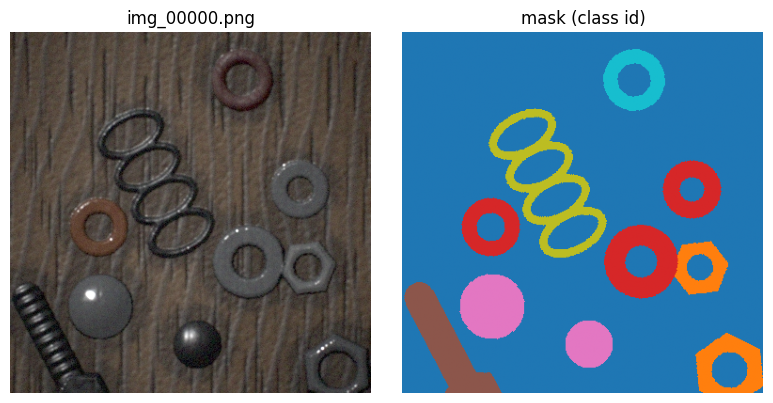

In [4]:
# Visualise one training image + its mask.
if train_files:
    fname = train_files[0]
    img = np.array(Image.open(os.path.join(TRAIN_IMG_DIR, fname)).convert("RGB"))
    mask = np.array(Image.open(os.path.join(TRAIN_MASK_DIR, fname)))   # DO NOT .convert("RGB") on masks
    print("unique mask values:", np.unique(mask))

    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(img); ax[0].set_title(fname); ax[0].axis("off")
    ax[1].imshow(mask, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1); ax[1].set_title("mask (class id)"); ax[1].axis("off")
    plt.tight_layout(); plt.show()


## 3. RLE encode/decode + competition metric

Copied verbatim from the problem statement (column-major / Fortran order). Run the
sanity check before generating any submission — this is the single most common source
of silent scoring errors.

In [5]:
def rle_encode(mask):
    """mask: a 384x384 boolean array -> RLE string."""
    px = np.asarray(mask, np.uint8).T.flatten()
    px = np.concatenate([[0], px, [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(str(int(x)) for x in runs)

def rle_decode(rle, size=384):
    """RLE string -> 384x384 uint8 array."""
    m = np.zeros(size * size, np.uint8)
    if not isinstance(rle, str) or not rle.strip():
        return m.reshape(size, size, order="F")
    a = np.asarray(rle.split(), np.int64)
    for s, l in zip(a[0::2], a[1::2]):
        m[s - 1: s - 1 + l] = 1
    return m.reshape(size, size, order="F")

# Sanity check on a random mask.
_rng = np.random.RandomState(0)
_test_mask = (_rng.rand(IMG_SIZE, IMG_SIZE) > 0.7).astype(np.uint8)
assert np.array_equal(rle_decode(rle_encode(_test_mask)), _test_mask.astype(np.uint8))
print("RLE round-trip sanity check passed.")


RLE round-trip sanity check passed.


In [6]:
def mean_dice_score(pred_label_map, true_label_map, num_classes=6, class_offset=1):
    """
    Competition metric for a single image: mean Dice over the 6 foreground classes.
    pred_label_map / true_label_map: HxW arrays of class ids (0..6).
    A class absent from both pred and truth scores 1.0 for that pair (empty == empty).
    """
    scores = []
    for c in range(class_offset, class_offset + num_classes):
        p = (pred_label_map == c)
        t = (true_label_map == c)
        inter = np.logical_and(p, t).sum()
        denom = p.sum() + t.sum()
        scores.append(1.0 if denom == 0 else (2.0 * inter) / denom)
    return float(np.mean(scores))


## 4. Dataset & augmentation

In [7]:
class SegDataset(Dataset):
    """
    Reads images/masks straight from PNG files.
    Augmentation: random horizontal/vertical flip + random 90-degree rotation,
    applied identically to image and mask (no external aug library needed).
    """
    def __init__(self, filenames, img_dir, mask_dir=None, train=True):
        self.filenames = filenames
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.train = train

    def __len__(self):
        return len(self.filenames)

    def _augment(self, img, mask):
        if random.random() < 0.5:
            img = np.ascontiguousarray(img[:, ::-1, :])
            mask = np.ascontiguousarray(mask[:, ::-1])
        if random.random() < 0.5:
            img = np.ascontiguousarray(img[::-1, :, :])
            mask = np.ascontiguousarray(mask[::-1, :])
        k = random.randint(0, 3)
        if k:
            img = np.ascontiguousarray(np.rot90(img, k, axes=(0, 1)))
            mask = np.ascontiguousarray(np.rot90(mask, k, axes=(0, 1)))
        return img, mask

    def __getitem__(self, idx):
        fname = self.filenames[idx]
        img = np.array(Image.open(os.path.join(self.img_dir, fname)).convert("RGB")).astype(np.float32)

        if self.mask_dir is not None:
            mask = np.array(Image.open(os.path.join(self.mask_dir, fname))).astype(np.int64)  # values 0..6
            if self.train:
                img, mask = self._augment(img, mask)
        else:
            mask = np.zeros(img.shape[:2], dtype=np.int64)

        img = img / 255.0
        img_t = torch.from_numpy(img.transpose(2, 0, 1)).float()
        mask_t = torch.from_numpy(mask).long()
        return img_t, mask_t, fname


In [8]:
all_train_files = sorted(os.listdir(TRAIN_IMG_DIR)) if os.path.isdir(TRAIN_IMG_DIR) else []
random.Random(SEED).shuffle(all_train_files)
n_val = max(1, int(len(all_train_files) * VAL_FRACTION))
val_files = all_train_files[:n_val]
train_files_split = all_train_files[n_val:]
print(f"train: {len(train_files_split)}  val: {len(val_files)}")

train_ds = SegDataset(train_files_split, TRAIN_IMG_DIR, TRAIN_MASK_DIR, train=True)
val_ds   = SegDataset(val_files, TRAIN_IMG_DIR, TRAIN_MASK_DIR, train=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, pin_memory=True)


train: 1800  val: 200


## 5. From-scratch U-Net

Standard encoder-decoder with skip connections. Every layer is randomly initialised
(Kaiming for conv weights) — **no pretrained encoder**, as required by the rules.

In [9]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=NUM_CLASSES, base=32):
        super().__init__()
        chs = [base, base * 2, base * 4, base * 8, base * 16]

        self.enc1 = DoubleConv(in_ch, chs[0])
        self.enc2 = DoubleConv(chs[0], chs[1])
        self.enc3 = DoubleConv(chs[1], chs[2])
        self.enc4 = DoubleConv(chs[2], chs[3])
        self.bottleneck = DoubleConv(chs[3], chs[4])
        self.pool = nn.MaxPool2d(2)

        self.up4 = nn.ConvTranspose2d(chs[4], chs[3], 2, stride=2)
        self.dec4 = DoubleConv(chs[4], chs[3])
        self.up3 = nn.ConvTranspose2d(chs[3], chs[2], 2, stride=2)
        self.dec3 = DoubleConv(chs[3], chs[2])
        self.up2 = nn.ConvTranspose2d(chs[2], chs[1], 2, stride=2)
        self.dec2 = DoubleConv(chs[2], chs[1])
        self.up1 = nn.ConvTranspose2d(chs[1], chs[0], 2, stride=2)
        self.dec1 = DoubleConv(chs[1], chs[0])

        self.out_conv = nn.Conv2d(chs[0], num_classes, 1)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out_conv(d1)


model = UNet(in_ch=3, num_classes=NUM_CLASSES, base=32).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"UNet parameters: {n_params:,}")

# Quick shape check
with torch.no_grad():
    _out = model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE))
    print("output shape:", _out.shape)   # expect (2, 7, 384, 384)


UNet parameters: 7,763,239
output shape: torch.Size([2, 7, 384, 384])


## 6. Loss: CrossEntropy + soft Dice

Dice loss is computed over the 6 **foreground** classes only (matching the competition
metric, which never scores the background class), and combined with pixel-wise
cross-entropy for stable early training.

In [10]:
def soft_dice_loss(logits, target, num_classes=NUM_CLASSES, ignore_bg=True, eps=1e-6):
    probs = F.softmax(logits, dim=1)
    target_onehot = F.one_hot(target, num_classes=num_classes).permute(0, 3, 1, 2).float()
    start = 1 if ignore_bg else 0
    dims = (0, 2, 3)
    inter = torch.sum(probs[:, start:] * target_onehot[:, start:], dims)
    union = torch.sum(probs[:, start:] + target_onehot[:, start:], dims)
    dice = (2 * inter + eps) / (union + eps)
    return 1 - dice.mean()

ce_loss_fn = nn.CrossEntropyLoss()

def combined_loss(logits, target):
    return ce_loss_fn(logits, target) + soft_dice_loss(logits, target)


## 7. Training loop

In [11]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    dice_scores = []
    for imgs, masks, _ in loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = model(imgs)
        loss = combined_loss(logits, masks)
        total_loss += loss.item() * imgs.size(0)

        preds = torch.argmax(logits, dim=1).cpu().numpy()
        masks_np = masks.cpu().numpy()
        for p, t in zip(preds, masks_np):
            dice_scores.append(mean_dice_score(p, t))

    avg_loss = total_loss / len(loader.dataset)
    avg_dice = float(np.mean(dice_scores))
    return avg_loss, avg_dice


In [12]:
# Start every training run clean: delete any checkpoint left over from a previous
# session/commit so there's no chance of silently reusing old weights.
if os.path.exists(CKPT_PATH):
    os.remove(CKPT_PATH)
    print(f"Removed stale checkpoint at {CKPT_PATH} before starting this run.")

RUN_ID = time.strftime("%Y-%m-%d %H:%M:%S")
print("Training run started:", RUN_ID)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

best_val_dice = -1.0
history = {"train_loss": [], "val_loss": [], "val_dice": []}

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    t0 = time.time()

    for imgs, masks, _ in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(imgs)
            loss = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * imgs.size(0)

    scheduler.step()
    train_loss = running_loss / len(train_loader.dataset)
    val_loss, val_dice = evaluate(model, val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    dt = time.time() - t0
    print(f"Epoch {epoch:3d}/{NUM_EPOCHS} | train_loss {train_loss:.4f} | "
          f"val_loss {val_loss:.4f} | val_dice {val_dice:.4f} | {dt:.1f}s")

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        # Save metadata alongside the weights so you can verify, at inference time,
        # exactly which run/epoch produced the checkpoint you're about to submit.
        torch.save({
            "model_state": model.state_dict(),
            "val_dice": val_dice,
            "epoch": epoch,
            "run_id": RUN_ID,
            "saved_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        }, CKPT_PATH)
        print(f"  -> new best val_dice {best_val_dice:.4f}, checkpoint saved.")

print("Best val dice this run:", best_val_dice, "| run_id:", RUN_ID)

Training run started: 2026-07-27 14:03:59
Epoch   1/50 | train_loss 1.2021 | val_loss 0.8138 | val_dice 0.5959 | 44.7s
  -> new best val_dice 0.5959, checkpoint saved.
Epoch   2/50 | train_loss 0.4633 | val_loss 0.4106 | val_dice 0.7998 | 45.0s
  -> new best val_dice 0.7998, checkpoint saved.
Epoch   3/50 | train_loss 0.2368 | val_loss 0.1991 | val_dice 0.8990 | 47.4s
  -> new best val_dice 0.8990, checkpoint saved.
Epoch   4/50 | train_loss 0.1595 | val_loss 0.1311 | val_dice 0.9352 | 48.5s
  -> new best val_dice 0.9352, checkpoint saved.
Epoch   5/50 | train_loss 0.1308 | val_loss 0.1853 | val_dice 0.9070 | 48.1s
Epoch   6/50 | train_loss 0.1110 | val_loss 0.1119 | val_dice 0.9444 | 47.9s
  -> new best val_dice 0.9444, checkpoint saved.
Epoch   7/50 | train_loss 0.1088 | val_loss 0.1019 | val_dice 0.9497 | 48.1s
  -> new best val_dice 0.9497, checkpoint saved.
Epoch   8/50 | train_loss 0.0919 | val_loss 0.3629 | val_dice 0.8619 | 47.9s
Epoch   9/50 | train_loss 0.0930 | val_loss 0.09

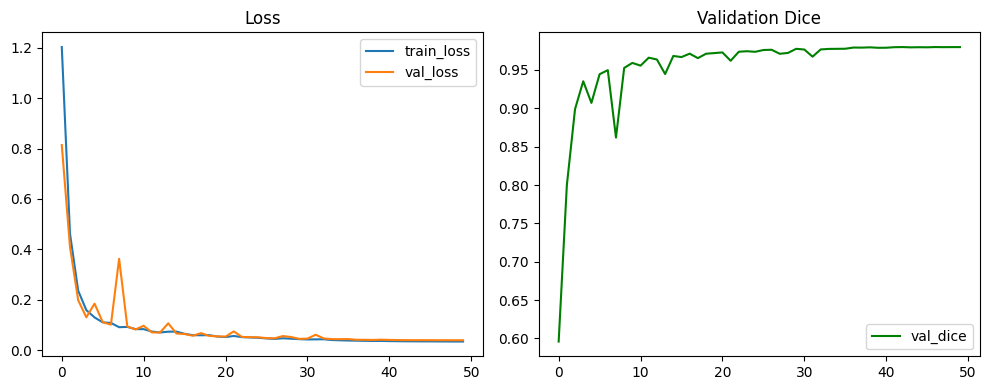

In [13]:
# Training curves
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history["train_loss"], label="train_loss")
ax[0].plot(history["val_loss"], label="val_loss")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["val_dice"], label="val_dice", color="green")
ax[1].set_title("Validation Dice"); ax[1].legend()
plt.tight_layout(); plt.show()


## 8. Inference on test set → submission.csv

Loads the best checkpoint, predicts an argmax class map per test image, converts each
foreground class into a binary mask, RLE-encodes it, and fills `sample_submission.csv`
in its exact given row order (so keys, order, and count all match what's required).

In [14]:
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
model.eval()

# Confirm this is actually the checkpoint from the run you just trained, not a stale
# one left over from a previous session -- compare run_id/epoch/val_dice against what
# the training cell printed above.
print(f"Loaded checkpoint: run_id={ckpt.get('run_id')} | epoch={ckpt.get('epoch')} | "
      f"val_dice={ckpt.get('val_dice'):.4f} | saved_at={ckpt.get('saved_at')}")
if 'RUN_ID' in globals():
    match = (ckpt.get('run_id') == RUN_ID)
    print(f"Matches this session's training run: {match}"
          + ("" if match else "  <-- WARNING: this checkpoint is from a DIFFERENT run than the training cell you last executed."))

test_files_sorted = sorted(os.listdir(TEST_IMG_DIR)) if os.path.isdir(TEST_IMG_DIR) else []
test_ds = SegDataset(test_files_sorted, TEST_IMG_DIR, mask_dir=None, train=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

pred_masks = {}   # filename -> HxW np.uint8 class-id array (argmax)
pred_probs = {}   # filename -> C x H x W float32 softmax probs (needed for the empty-mask fallback below)

with torch.no_grad():
    for imgs, _, fnames in test_loader:
        imgs = imgs.to(DEVICE)
        logits = model(imgs)
        probs = F.softmax(logits, dim=1).cpu().numpy().astype(np.float32)
        preds = torch.argmax(logits, dim=1).cpu().numpy().astype(np.uint8)
        for p, pr, fname in zip(preds, probs, fnames):
            pred_masks[fname] = p
            pred_probs[fname] = pr

print(f"Predicted masks for {len(pred_masks)} test images.")

Loaded checkpoint: run_id=2026-07-27 14:03:59 | epoch=47 | val_dice=0.9798 | saved_at=2026-07-27 14:41:40
Matches this session's training run: True
Predicted masks for 500 test images.


In [15]:
sample_sub = pd.read_csv(SAMPLE_SUB)
print(sample_sub.shape)
print(sample_sub.head())

def ensure_nonempty(binary_mask, prob_channel):
    """
    Every class is guaranteed present in every image (per the problem statement), so a
    fully empty predicted mask is always a model mistake, never a correct answer.
    A truly empty RLE string also becomes a blank CSV field, which Kaggle's own
    pd.read_csv() reads back as NaN -> "submission contains null values". So if the
    argmax mask has zero pixels for a class, fall back to the single most confident
    pixel for that class instead of leaving it empty.
    """
    if binary_mask.sum() == 0:
        binary_mask = binary_mask.copy()
        idx = np.unravel_index(np.argmax(prob_channel), prob_channel.shape)
        binary_mask[idx] = True
    return binary_mask

encoded = {}
n_fallback = 0
for fname, mask in pred_masks.items():
    probs = pred_probs[fname]
    for class_id, class_name in CLASS_NAMES.items():
        if class_id == 0:
            continue  # background is never a submission row
        binary = (mask == class_id)
        if binary.sum() == 0:
            n_fallback += 1
        binary = ensure_nonempty(binary, probs[class_id])
        key = f"{fname}_{class_name}"
        encoded[key] = rle_encode(binary)

print(f"Classes with zero predicted pixels (fallback applied): {n_fallback} / {len(encoded)}")

def lookup(image_class_id):
    # This should never actually be hit if pred_masks covers every test image + class,
    # but keep a safe (non-empty, valid) fallback rather than leaving a blank field.
    return encoded.get(image_class_id, "1 1")

sample_sub["EncodedPixels"] = sample_sub["ImageId_ClassId"].map(lookup)

n_empty = (sample_sub["EncodedPixels"].astype(str).str.strip() == "").sum()
n_null  = sample_sub["EncodedPixels"].isna().sum()
print(f"Empty-string rows: {n_empty} | NaN rows: {n_null} (both must be 0 before submitting)")
assert n_empty == 0 and n_null == 0, "Submission still contains empty/null EncodedPixels values."

sample_sub.to_csv(SUBMISSION_PATH, index=False)
print(f"Saved {SUBMISSION_PATH}")
sample_sub.head(12)

(3000, 2)
              ImageId_ClassId EncodedPixels
0       img_00001.png_hex_nut           1 1
1        img_00001.png_washer           1 1
2          img_00001.png_bolt           1 1
3  img_00001.png_ball_bearing           1 1
4        img_00001.png_spring           1 1
Classes with zero predicted pixels (fallback applied): 0 / 3000
Empty-string rows: 0 | NaN rows: 0 (both must be 0 before submitting)
Saved submission.csv


,ImageId_ClassId,EncodedPixels
0,img_00001.png_hex_nut,16686 1 17069 6 17450 11 17833 13 18215 16 185...
1,img_00001.png_washer,1829 10 2208 20 2590 25 2971 31 3353 34 3735 3...
2,img_00001.png_bolt,31680 1 32054 8 32063 2 32437 15 32820 24 3320...
3,img_00001.png_ball_bearing,20282 4 20660 13 21041 19 21423 26 21805 31 22...
4,img_00001.png_spring,22 25 403 29 786 31 1168 34 1550 37 1933 39 23...
5,img_00001.png_o_ring,73502 14 73882 23 74264 27 74646 32 75027 36 7...
6,img_00005.png_hex_nut,75478 7 75848 1 75851 18 76221 3 76225 29 7659...
7,img_00005.png_washer,37 70 420 72 803 74 1186 75 1570 32 1604 1 160...
8,img_00005.png_bolt,32841 3 33224 7 33607 12 33990 17 34373 21 347...
9,img_00005.png_ball_bearing,206 57 589 58 972 61 1355 62 1738 64 2122 65 2...


### Final checks before you submit
- Row count and `ImageId_ClassId` order must exactly match `sample_submission.csv` (handled above via `.map` on the original frame).
- Re-run the RLE sanity check cell if you touch the encode/decode functions.
- Trust your local validation Dice over the public leaderboard number — it's only 30% of the test set.
- Confirm no pretrained weights were loaded anywhere (`UNet` is initialised from scratch via `_init_weights`).
